# Example 4: two coupled dissipative modes, coherent versus action detection

Two weakly anharmonic bosonic modes, truncated to three levels each (nine states), are coupled and exposed to five kinds of dissipation: pure dephasing, a relaxation cascade, population transfer from the upper to the lower mode, and radiative decay. The same dynamics can be read out in several ways, and the readout changes the lines that the spectrum shows. In this notebook you will:

- build the nine-state model with QuTiP and give the solver collapse channels whose rates are stored separately from their operators;
- check that the ground state is stationary, and read the decay rates that the channels imply, first from the solver and then from the eigenvalues of the QuTiP Liouvillian;
- compute the third-order rephasing response from three pathways (written by hand, then generated with UFSS);
- detect the same pathways with four readouts from one propagation: the emitted field (polarization) and three action readouts, a photoluminescence-type projector on the one-quantum states with equal and with unbalanced weights, and the total excitation number;
- compare the antidiagonal linewidths of the readouts at two transfer rates;
- verify two exact results that do not depend on how the spectrum looks.

The model follows the two-mode model of the perspective on detection-dependent dephasing in two-dimensional electronic spectroscopy (Paiva-Ortega et al., 2026). Natural units: $\hbar=1$, energies and rates in eV, times in eV$^{-1}$.

## 0. Imports

`qutip` builds the physical operators. `qudpy_fdgf` provides the model, the solver, the pathways and the observables. UFSS (Section 4) is imported where it is used. `matplotlib` draws the figures, `scipy` fits the antidiagonal cuts of Section 6.

In [1]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

from qudpy_fdgf import (
    EigenbasisKModel,
    FrequencyPathway,
    ObservableSpec,
    SpectroscopySolver,
    standard_nq_protocol,
)

## 1. Physical model

Each mode $m\in\{a,b\}$ has creation operator $b_m^\dagger$ and number operator $n_m=b_m^\dagger b_m$, truncated to the levels $0,1,2$. The Hamiltonian and the transition operator are

$$
H=\sum_m\Big[\omega_m n_m+\tfrac{\Delta}{2}\,n_m(n_m-1)\Big]+J\left(b_a^\dagger b_b+b_b^\dagger b_a\right),
\qquad
\mu=\sum_m d_m\left(b_m+b_m^\dagger\right).
$$

$\Delta$ is the anharmonicity: it lifts the two-quantum level of each mode by $\Delta$, so that the excited-state absorption is displaced from the stimulated emission. $J$ couples the two modes. The ground state is $|g\rangle=|0,0\rangle$, the one-quantum eigenstates $|e_a\rangle\approx|1,0\rangle$ and $|e_b\rangle\approx|0,1\rangle$ lie near $\omega_a=1.0$ and $\omega_b=1.2$ eV.

The dynamics follow the Lindblad (GKSL) generator $\mathcal L[\rho]=-i[H,\rho]+\sum_c\gamma_c\big(L_c\rho L_c^\dagger-\tfrac12\{L_c^\dagger L_c,\rho\}\big)$ with seven channels. The rate $\gamma_c$ is a separate number: it is never folded into $L_c$.

| Channel | $L_c$ | Rate $\gamma_c$ | Effect |
|---|---|---|---|
| pure dephasing (each mode) | $n_m$ | $\gamma_\phi=10$ meV | the coherence between levels $n$ and $n'$ decays at $\gamma_\phi(n-n')^2/2$, so $|0\rangle\langle1|$ at $\gamma_\phi/2$ |
| relaxation (each mode) | $b_m$ | $k=1$ meV | level $n$ decays to $n-1$ at $nk$: $1\to0$ at $k$, $2\to1$ at $2k$ |
| transfer, upper to lower mode | $|1_a0_b\rangle\langle0_a1_b|$ | $k_{ba}=5$ meV | downhill transfer within the one-quantum manifold, no uphill return |
| radiative decay (each mode) | $|0\rangle\langle1|_m$ | $k_{\rm rad}=0.1$ meV | emission from the one-quantum level of the mode |

The other parameters are $J=1$ meV, $\Delta=10$ meV and $d_a=d_b=1$.

The readouts of Section 5 use three detector operators besides the transition operator $\mu$: the projector $A_{\rm PL}=|e_a\rangle\langle e_a|+|e_b\rangle\langle e_b|$ on the one-quantum eigenstates (a photoluminescence-type readout, blind to the two-quantum population), the unbalanced projector $2|e_a\rangle\langle e_a|+|e_b\rangle\langle e_b|$, and the excitation number $N=n_a+n_b$.

In [2]:
# 1. Model: QuTiP operators, two modes with three levels each (hbar = 1, energies in eV)
omega_a, omega_b = 1.0, 1.2      # mode frequencies (eV)
coupling = 0.001                 # intermode coupling J
anharmonicity = 0.010            # Delta: lifts the two-quantum level of each mode
gamma_phi = 0.010                # pure-dephasing rate
k_relax = 0.001                  # relaxation rate 1 -> 0 (2 -> 1 is twice as fast)
k_rad = 0.0001                   # radiative decay rate

levels = 3
a = qt.tensor(qt.destroy(levels), qt.qeye(levels))
b = qt.tensor(qt.qeye(levels), qt.destroy(levels))
n_a, n_b = a.dag() * a, b.dag() * b
one = qt.qeye([levels, levels])

H = (omega_a * n_a + omega_b * n_b
     + 0.5 * anharmonicity * (n_a * (n_a - one) + n_b * (n_b - one))
     + coupling * (a.dag() * b + b.dag() * a))
mu_plus = a.dag() + b.dag()                 # raising part of the transition operator
mu = mu_plus + mu_plus.dag()

drop = qt.Qobj(np.array([[0, 1, 0], [0, 0, 0], [0, 0, 0]]))   # |0><1| on one mode
a_drop = qt.tensor(drop, qt.qeye(levels))
b_drop = qt.tensor(qt.qeye(levels), drop)


def collapse_channels(k_transfer):
    # (operator, rate) pairs; the transfer rate is the parameter that Section 5 varies
    return [
        (n_a, gamma_phi), (n_b, gamma_phi),            # pure dephasing
        (a, k_relax), (b, k_relax),                    # relaxation cascade
        (a_drop.dag() * b_drop, k_transfer),           # transfer b -> a
        (a_drop, k_rad), (b_drop, k_rad),              # radiative decay
    ]


# Detector operators of the action readouts
energies, eigenstates = H.eigenstates()
e_a, e_b = eigenstates[1], eigenstates[2]       # the two one-quantum eigenstates
A_PL = e_a * e_a.dag() + e_b * e_b.dag()
A_PL_unbalanced = 2 * e_a * e_a.dag() + e_b * e_b.dag()
N_exc = n_a + n_b
print("lowest energies (eV):", np.round(energies[:4], 4))

lowest energies (eV): [0.   1.   1.2  2.01]


## 2. Model and solver

`EigenbasisKModel` takes the Hamiltonian, the transition operator and the collapse channels as `(operator, rate)` pairs. The raising part `j_plus_array` of the transition operator is given explicitly, as in Example 3, so that the pathway algebra does not depend on a sign rule. The dictionary `observable_op_arrays` names the operators that the readouts of Section 5 will contract.

The solver evaluates the response with resolvents $[(\eta-i\omega)\mathbb 1-\mathcal L]^{-1}$. The regularization $\eta=10\ \mu$eV adds a numerical width to every pole; it is small against the physical widths of several meV, so that the lines in the maps are those of the generator. The `dense` backend stores the full Liouville matrix ($81\times81$), which is the right choice here.

In [3]:
# 2. Solver: model with (operator, rate) channels, backend, broadening eta
def build_model(k_transfer):
    return EigenbasisKModel(
        H,
        mu,
        c_ops_raw=collapse_channels(k_transfer),
        j_plus_array=mu_plus,
        j_minus_array=mu_plus.dag(),
        detection_op_array=mu,
        observable_op_arrays={
            "polarization": mu,
            "A_PL": A_PL,
            "A_PL_unbalanced": A_PL_unbalanced,
            "N_exc": N_exc,
        },
    )


k_transfer = 0.005                 # transfer rate of the baseline case (eV)
model = build_model(k_transfer)

eta = 1e-5                         # resolvent broadening (eV)
solver = SpectroscopySolver(backend="dense", eta=eta)
solver.feed_model(model)           # default initial state: the ground state

## 3. Initial state and decay rates

The calculation starts from $\rho_0=|g\rangle\langle g|$. At zero temperature it must be stationary under $\mathcal L$: no channel moves population out of $|0,0\rangle$. QuTiP builds the same generator with `qt.liouvillian`, which wants $\sqrt{\gamma_c}\,L_c$ as collapse operator.

The solver can also report the decay rates that the declared channels imply, in the eigenbasis of $H$ (`solver.decay_rates()`). They check the physical meaning of each rate before any spectrum is computed. Here we compare the decay rate of the coherences $|g\rangle\langle e_a|$ and $|g\rangle\langle e_b|$, which set the widths of the two diagonal peaks, with the eigenvalues of the QuTiP Liouvillian: the eigenvector with the largest overlap on each coherence has the eigenvalue $-\Gamma+i\omega$.

In [4]:
# 3. Ground state and rates
c_ops = [np.sqrt(rate) * op for op, rate in collapse_channels(k_transfer)]   # QuTiP wants sqrt(rate) * L
liouvillian = qt.liouvillian(H, c_ops)
ground = eigenstates[0]
drho = qt.vector_to_operator(liouvillian * qt.operator_to_vector(ground * ground.dag()))
print(f"max |L[rho_0]| = {np.abs(drho.full()).max():.1e}")
assert np.abs(drho.full()).max() < 1e-14

rates = solver.decay_rates()
eigenvalues, eigenvectors = np.linalg.eig(liouvillian.full())
print(f"{'coherence':<14}{'solver decay_rates (meV)':>26}{'QuTiP eigenvalue (meV)':>26}")
for label, state, index in (("g-e_a", e_a, 1), ("g-e_b", e_b, 2)):
    target = qt.operator_to_vector(ground * state.dag()).full().ravel()
    overlap = np.abs(target.conj() @ eigenvectors) / np.linalg.norm(eigenvectors, axis=0) / np.linalg.norm(target)
    qutip_rate = -eigenvalues[np.argmax(overlap)].real
    print(f"{label:<14}{1e3 * rates.coherence_decay[0, index]:>26.5f}{1e3 * qutip_rate:>26.5f}")
    assert abs(rates.coherence_decay[0, index] - qutip_rate) < 1e-8

max |L[rho_0]| = 0.0e+00
coherence       solver decay_rates (meV)    QuTiP eigenvalue (meV)
g-e_a                            5.55006                   5.55006
g-e_b                            8.04994                   8.04994


The coherence $|g\rangle\langle e_a|$ decays at $\gamma_\phi/2+k/2+k_{\rm rad}/2=5.55$ meV. The coherence $|g\rangle\langle e_b|$ also loses the population that the transfer channel takes from $e_b$, an extra $k_{ba}/2=2.5$ meV, so it decays at $8.05$ meV. The solver and QuTiP agree.

## 4. Third-order rephasing pathways

The rephasing $\chi^{(3)}$ signal of a model with a two-quantum manifold has three pathways, each named by its ordered light–matter interactions ($B$ acts on the bra side, $K$ on the ket side, $u$ raises and $d$ lowers):

$$R_{\rm GSB}=(B_u,B_d,K_u)\ \text{(ground-state bleach)},\qquad R_{\rm SE}=(B_u,K_u,B_d)\ \text{(stimulated emission)},\qquad R_{\rm ESA}=(B_u,K_u,K_u)\ \text{(excited-state absorption)}.$$

All three follow the coherence orders $q=(-1,0,+1)$. The excited-state absorption is displaced from the stimulated emission by the anharmonicity $\Delta$ and has the opposite sign.

**Written by hand.** A `FrequencyPathway` is just the list of interactions.

In [5]:
# 3. Pathways: ordered interaction labels
pathways = (
    FrequencyPathway(name="R_GSB", interactions=("Bu", "Bd", "Ku"), component="rephasing", detection="polarization"),
    FrequencyPathway(name="R_SE", interactions=("Bu", "Ku", "Bd"), component="rephasing", detection="polarization"),
    FrequencyPathway(name="R_ESA", interactions=("Bu", "Ku", "Ku"), component="rephasing", detection="polarization"),
)

**Generated with UFSS.** UFSS builds the diagrams from a phase-discrimination pattern (one `(bra, ket)` count per pulse), and `translate_ufss_diagrams` converts them to `FrequencyPathway` objects. `maximum_manifold = 2` keeps the diagrams that reach the two-quantum manifold of this model.

In [6]:
import ufss
from qudpy_fdgf import translate_ufss_diagrams

diagram_generator = ufss.DiagramGenerator()
diagram_generator.set_phase_discrimination([(0, 1), (1, 0), (1, 0)])   # rephasing
diagram_generator.maximum_manifold = 2
diagram_generator.efield_times = [np.array([0.0, 0.0])] * 3
ufss_diagrams = diagram_generator.get_diagrams(np.arange(3, dtype=float))

ufss_pathways = translate_ufss_diagrams(ufss_diagrams, component="rephasing", detection="polarization")
for pathway in ufss_pathways:
    labels = tuple(interaction.label for interaction in pathway.interactions)
    print(f"{pathway.name}: {labels}, q = {pathway.coherence_orders}")

# The generated pathways are the ones written by hand above (UFSS returns them in its own order).
generated = {tuple(i.label for i in p.interactions) for p in ufss_pathways}
assert generated == {tuple(i.label for i in p.interactions) for p in pathways}

P1: ('Bu', 'Ku', 'Ku'), q = (-1, 0, 1)
P2: ('Bu', 'Ku', 'Bd'), q = (-1, 0, 1)
P3: ('Bu', 'Bd', 'Ku'), q = (-1, 0, 1)


## 5. Protocol and spectra

`standard_nq_protocol` says how the three interactions and the intervals between them are treated: the first interval is the one-quantum coherence, Fourier-transformed to `omega_1q`; the third is the emitted coherence, transformed to `omega_emit`; the waiting time $t_2$ stays in the time domain and is fixed with `fixed_coordinates`. The rephasing peaks sit at $\omega_{1Q}\approx-\omega_m$ and $\omega_{\rm emit}\approx+\omega_{m'}$ for $m,m'\in\{a,b\}$: two diagonal peaks and two cross peaks.

The solver propagates the three field interactions once. Several observables then read the same propagated states:

- `"polarization"`: the emitted field, the optical coherence contracted with $\mu$;
- `ObservableSpec.action` with the operators `A_PL`, `A_PL_unbalanced` and `N_exc`: a fourth interaction projects the final coherence ($q=+1$) onto a population ($q=0$), and the population is read with the detector operator. Two alternatives bring the coherence to $q=0$, a raising interaction on the bra side ($B_u$) and a lowering interaction on the ket side ($K_d$); `fourth_interaction=("Bu", "Kd")` sums them.

The fourth interaction belongs to the observable, not to the pathway, which stays third order. The grid has $201\times201$ points over 0.4 eV on each axis, 2 meV apart, to resolve lines about 6 meV wide.

In [7]:
# 4. Protocol: t1 and t3 in frequency, the waiting time t2 in time
protocol = standard_nq_protocol(
    order=1,
    nq_interval=1,
    detection_interval=3,
    n_interactions=3,
    nq_axis="omega_1q",
    detection_axis="omega_emit",
)
t2 = 10.0                          # population waiting time (eV^-1)
omega_1q = np.linspace(-1.30, -0.90, 201)
omega_emit = np.linspace(0.90, 1.30, 201)

# 5. Observables: one propagation, four readouts
readout = ("Bu", "Kd")             # both alternatives that turn the coherence into a population
observables = {
    "polarization": "polarization",
    "action_PL": ObservableSpec.action("action_PL", fourth_interaction=readout, operator="A_PL"),
    "action_PL_unbalanced": ObservableSpec.action(
        "action_PL_unbalanced", fourth_interaction=readout, operator="A_PL_unbalanced"
    ),
    "action_N": ObservableSpec.action("action_N", fourth_interaction=readout, operator="N_exc"),
}
result = solver.generate_spectrum(
    protocol,
    axes={"omega_1q": omega_1q, "omega_emit": omega_emit},
    fixed_coordinates={"t2": t2},
    pathways=pathways,
    observables=observables,
)


def total(result, name):
    # the three pathways add up to the rephasing response
    return sum(result.observables[name][pathway.name] for pathway in pathways)


print("array shape (omega_1q, omega_emit):", total(result, "polarization").shape)

array shape (omega_1q, omega_emit): (201, 201)


## 6. Coherent emission versus action detection

We draw the total rephasing response of each readout, $|S|$, each panel normalized to its own maximum. The dashed line marks the antidiagonal $\omega_{\rm emit}=-\omega_{1Q}$ on which the diagonal peaks lie.

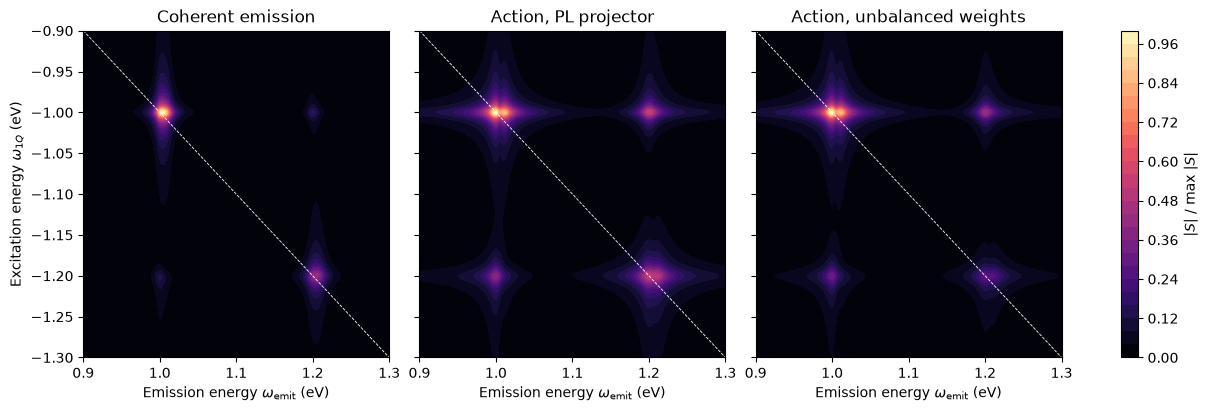

In [8]:
panels = {
    "Coherent emission": total(result, "polarization"),
    r"Action, PL projector": total(result, "action_PL"),
    r"Action, unbalanced weights": total(result, "action_PL_unbalanced"),
}
maps_figure, map_axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True, constrained_layout=True)
for axis, (title, signal) in zip(map_axes, panels.items()):
    image = axis.contourf(omega_emit, omega_1q, np.abs(signal) / np.abs(signal).max(), levels=30, cmap="magma")
    axis.plot(omega_emit, -omega_emit, "w--", linewidth=0.6)
    axis.set_xlim(omega_emit[0], omega_emit[-1])
    axis.set_ylim(omega_1q[0], omega_1q[-1])
    axis.set_title(title)
    axis.set_xlabel(r"Emission energy $\omega_{\mathrm{emit}}$ (eV)")
map_axes[0].set_ylabel(r"Excitation energy $\omega_{1Q}$ (eV)")
maps_figure.colorbar(image, ax=map_axes, label=r"$|S|$ / max $|S|$")

The coherent map shows the two diagonal peaks and the cross peaks. The PL projector gives the same positions with different relative weights and broader lines, because it does not see the two-quantum population that the excited-state absorption leaves behind. Doubling the weight of $e_a$ raises the peaks at $\omega_{\rm emit}=\omega_a$ against those at $\omega_b$.

To compare the lines, we cut each diagonal peak along the antidiagonal, $(\omega_{1Q},\omega_{\rm emit})=(-\omega_m+x,\ \omega_m+x)$, which for a single pathway with decay rate $\Gamma$ gives $|S|\propto1/(\Gamma^2+x^2)$. The solver evaluates any list of frequencies, so the cut is computed exactly and without interpolation: a square patch of $241\times241$ points, 0.25 meV apart, centred on $(-\omega_m,\omega_m)$ and with the same offsets $x$ on both axes. Its diagonal is the antidiagonal cut. A Lorentzian with an offset is fitted to $|S|$ along the cut, and its half width at half maximum is the linewidth.

The second case doubles the transfer rate: only the generator changes, the pathways and the readouts are the same.

In [9]:
offsets = np.linspace(-0.030, 0.030, 241)          # antidiagonal offsets x (eV), 0.25 meV apart


def antidiagonal_cuts(solver, peak):
    # Square patch centred on (-peak, peak): its diagonal is the cut (-peak + x, peak + x)
    patch = solver.generate_spectrum(
        protocol,
        axes={"omega_1q": -peak + offsets, "omega_emit": peak + offsets},
        fixed_coordinates={"t2": t2},
        pathways=pathways,
        observables=observables,
    )
    cuts = {name: np.diag(total(patch, name)) for name in observables}
    cuts["R_GSB"] = np.diag(patch.observables["polarization"]["R_GSB"])
    return cuts


def lorentzian_hwhm(cut):
    # Lorentzian plus offset fitted to |S| along the cut: half width at half maximum in meV
    magnitude = np.abs(cut)

    def lorentzian(x, amplitude, width, center, offset):
        return offset + amplitude * width**2 / ((x - center) ** 2 + width**2)

    start = (magnitude.max(), 0.006, 0.0, magnitude.min())
    bounds = ([0.0, 5e-4, -0.012, 0.0], [np.inf, 0.05, 0.012, np.inf])
    parameters, _ = curve_fit(lorentzian, offsets, magnitude, p0=start, bounds=bounds, maxfev=20000)
    return 1e3 * parameters[1]


solver_fast = SpectroscopySolver(backend="dense", eta=eta)
solver_fast.feed_model(build_model(0.010))
solvers = {"k_ba = 5 meV": solver, "k_ba = 10 meV": solver_fast}
cuts = {
    (case, peak): antidiagonal_cuts(case_solver, peak)
    for case, case_solver in solvers.items()
    for peak in (omega_a, omega_b)
}

readout_names = {
    "polarization": "coherent emission",
    "action_PL": "action, PL projector",
    "action_PL_unbalanced": "action, unbalanced",
    "action_N": "action, excitation number",
}
widths = {
    (name, case, peak): lorentzian_hwhm(cuts[(case, peak)][name])
    for name in readout_names
    for case in solvers
    for peak in (omega_a, omega_b)
}
print(f"{'HWHM (meV)':<28}" + "".join(f"{case + ', w_a':>20}{case + ', w_b':>20}" for case in solvers))
for name, label in readout_names.items():
    row = [widths[(name, case, peak)] for case in solvers for peak in (omega_a, omega_b)]
    print(f"{label:<28}" + "".join(f"{value:>20.2f}" for value in row))

HWHM (meV)                     k_ba = 5 meV, w_a   k_ba = 5 meV, w_b  k_ba = 10 meV, w_a  k_ba = 10 meV, w_b
coherent emission                           5.65                7.30                5.65                9.08
action, PL projector                        7.22               10.28                7.24               12.51
action, unbalanced                          7.23               10.18                7.24               12.24
action, excitation number                   5.65                7.30                5.65                9.08


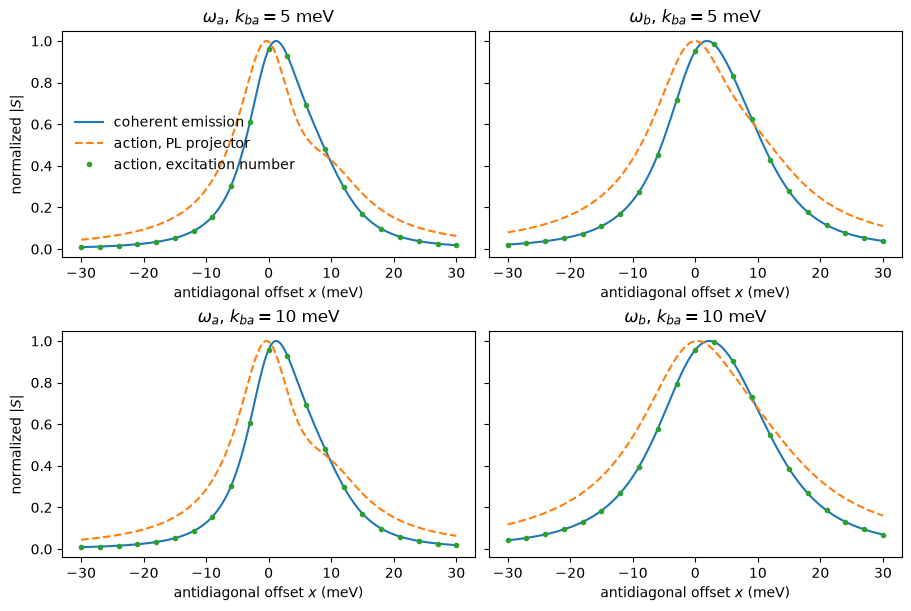

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey="row", constrained_layout=True)
styles = {
    "polarization": dict(linestyle="-"),
    "action_PL": dict(linestyle="--"),
    "action_N": dict(linestyle="none", marker="o", markersize=3, markevery=12),   # lies on the coherent curve
}
for row, case in enumerate(solvers):
    rate = case.split("= ")[1].replace(" meV", "")
    for column, (peak, label) in enumerate(((omega_a, r"\omega_a"), (omega_b, r"\omega_b"))):
        for name, style in styles.items():
            magnitude = np.abs(cuts[(case, peak)][name])
            axes[row, column].plot(1e3 * offsets, magnitude / magnitude.max(), label=readout_names[name], **style)
        axes[row, column].set_title(rf"${label}$, $k_{{ba}}={rate}$ meV")
        axes[row, column].set_xlabel("antidiagonal offset $x$ (meV)")
axes[0, 0].set_ylabel("normalized $|S|$")
axes[1, 0].set_ylabel("normalized $|S|$")
axes[0, 0].legend(frameon=False)
cuts_figure = fig

Three things stand out. The excitation-number readout has exactly the width of the coherent emission; the PL projector is broader than both at each diagonal peak; and raising the transfer rate widens the peak at $\omega_b$, whose population leaves, while the peak at $\omega_a$ barely changes. The next section shows why the first of these is an identity and not an accident.

## 7. Verification

Two results hold for this model whatever the spectrum looks like.

1. **The excitation number reads the coherent signal.** With the readout alternatives summed, the action signal with the detector $N=n_a+n_b$ is $-i$ times the polarization, pathway by pathway: $S_N^{(4)}=-i\,S_{\rm pol}^{(3)}$. The reason is algebraic. Summed, the two alternatives act on the final state as a commutator with the lowering part $\mu_-$ of the transition operator, and $\mathrm{Tr}\,(N[\mu_-,\rho])=\mathrm{Tr}\,([N,\mu_-]\rho)=-\mathrm{Tr}\,(\mu_-\rho)$, which is the polarization of the $q=+1$ coherence left by the three pulses, up to the phase of the interaction. The detector is read right after the fourth interaction, so dissipation does not enter; after a delay, relaxation would change $N$ and the identity would fail. Each readout alternative alone breaks the identity; their sum restores it. This is the many-level counterpart of the identity $S_{\rm pop}^{(4)}=-i\,S_{\rm pol}^{(3)}$ of Example 1. A detector that is not the excitation number, such as $A_{\rm PL}$, has no such relation to the coherent signal, which is why its lines differ.
2. **A single pathway has the width of the declared rates.** For the ground-state bleach alone, the antidiagonal cut of each diagonal peak is a Lorentzian whose half width is the decay rate of the coherence plus $\eta$, as reported in Section 3, to about 1 %: the tail of the other peak, 0.2 eV away, accounts for the difference. In the sum of the three pathways the excited-state absorption, displaced by $\Delta=10$ meV and of opposite sign, changes the apparent width: the half widths of the total response in Section 6 are not the decay rates.

In [11]:
# 6. Results: complex arrays indexed [omega_1q, omega_emit]
S_pol = total(result, "polarization")
S_N = total(result, "action_N")
identity_error = np.max(np.abs(S_N + 1j * S_pol)) / np.max(np.abs(S_pol))
print(f"max|S_N + i S_pol| / max|S_pol| = {identity_error:.1e}")
for pathway in pathways:
    pol = result.observables["polarization"][pathway.name]
    error = np.max(np.abs(result.observables["action_N"][pathway.name] + 1j * pol)) / np.max(np.abs(pol))
    print(f"   {pathway.name}: {error:.1e}")
assert identity_error < 1e-12

# Each readout alternative alone breaks the identity
single = {
    alternative: solver.generate_spectrum(
        protocol,
        axes={"omega_1q": omega_1q, "omega_emit": omega_emit},
        fixed_coordinates={"t2": t2},
        pathways=pathways,
        observables={"action_N": ObservableSpec.action("action_N", fourth_interaction=alternative, operator="N_exc")},
    )
    for alternative in readout
}
for alternative, single_result in single.items():
    deviation = np.max(np.abs(total(single_result, "action_N") + 1j * S_pol)) / np.max(np.abs(S_pol))
    print(f"readout {alternative} alone: max|S_N + i S_pol| / max|S_pol| = {deviation:.2f}")

max|S_N + i S_pol| / max|S_pol| = 3.3e-16
   R_GSB: 1.3e-16
   R_SE: 1.4e-16
   R_ESA: 3.5e-16
readout Bu alone: max|S_N + i S_pol| / max|S_pol| = 0.91
readout Kd alone: max|S_N + i S_pol| / max|S_pol| = 1.71


In [12]:
# The ground-state bleach alone has the half width of the coherence decay rate plus eta
print(f"{'':<8}{'HWHM of R_GSB (meV)':>22}{'decay rate + eta (meV)':>26}")
for label, peak, index in (("w_a", omega_a, 1), ("w_b", omega_b, 2)):
    measured = lorentzian_hwhm(cuts[("k_ba = 5 meV", peak)]["R_GSB"])
    expected = 1e3 * (rates.coherence_decay[0, index] + eta)
    print(f"{label:<8}{measured:>22.3f}{expected:>26.3f}")
    assert abs(measured / expected - 1) < 0.02

           HWHM of R_GSB (meV)    decay rate + eta (meV)
w_a                      5.525                     5.560
w_b                      7.975                     8.060


## 8. Save the results

The arrays go into one `.npz` file and the figures into PDF files, in `validation/results/`. They are the reference for the analysis of this example.

In [13]:
from pathlib import Path

results = Path("../validation/results")
(results / "data").mkdir(parents=True, exist_ok=True)
(results / "figure").mkdir(parents=True, exist_ok=True)

arrays = {f"map_{name}": total(result, name) for name in observables}          # baseline maps
arrays["map_polarization_R_GSB"] = result.observables["polarization"]["R_GSB"]
for case, peak in cuts:                                                         # antidiagonal cuts
    tag = f"{case.split('= ')[1].replace(' ', '')}_{'a' if peak == omega_a else 'b'}"
    for name, cut in cuts[(case, peak)].items():
        arrays[f"cut_{name}_{tag}"] = cut
np.savez(
    results / "data" / "example4.npz",
    omega_a=omega_a, omega_b=omega_b, coupling=coupling, anharmonicity=anharmonicity,
    gamma_phi=gamma_phi, k_relax=k_relax, k_rad=k_rad, eta=eta, t2=t2,
    omega_1q=omega_1q, omega_emit=omega_emit, offsets=offsets,
    hwhm_meV=np.array([[[widths[(name, case, peak)] for peak in (omega_a, omega_b)] for case in solvers]
                       for name in readout_names]),               # [readout, transfer case, peak]
    **arrays,
)
maps_figure.savefig(results / "figure" / "example4_maps.pdf", bbox_inches="tight")
cuts_figure.savefig(results / "figure" / "example4_cuts.pdf", bbox_inches="tight")
print("saved", results / "data" / "example4.npz")

saved ..\validation\results\data\example4.npz


## Summary

- The model is built with QuTiP: two anharmonic modes of three levels, a hand-built list of seven `(operator, rate)` channels.
- The ground state is stationary, and the coherence decay rates that the channels imply (5.55 and 8.05 meV for the two diagonal peaks) agree between `solver.decay_rates()` and the eigenvalues of the QuTiP Liouvillian.
- The three rephasing pathways, written by hand or generated with UFSS, are propagated once; polarization and three action readouts read the same states.
- The readout changes the lines: the PL projector, which does not see the two-quantum population, gives broader diagonal peaks than the coherent emission, and the transfer rate widens the peak whose population leaves.
- The excitation-number readout reproduces the coherent signal exactly, $S_N=-i\,S_{\rm pol}$ to machine precision, with dissipation present; each readout alternative alone breaks it.
- A single pathway has the width of the declared rates; the apparent width of the sum differs, because of the excited-state absorption.